# 01 — Eksplorasi Dataset WisataFinder

Notebook ini digunakan untuk memahami karakteristik dataset
destinasi wisata sebelum membangun sistem temu kembali informasi
menggunakan TF-IDF dan Cosine Similarity.

In [2]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().parent
DATA_PATH = PROJECT_ROOT / "data" / "raw" / "tourism_with_id.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset berhasil dibaca!")
print("Lokasi dataset:", DATA_PATH)
print("Ukuran dataset:", df.shape)

display(df.head())

Dataset berhasil dibaca!
Lokasi dataset: D:\WisataFinder\data\raw\tourism_with_id.csv
Ukuran dataset: (437, 13)


,Place_Id,Place_Name,Description,Category,City,Price,Rating,Time_Minutes,Coordinate,Lat,Long,Unnamed: 11,Unnamed: 12
0,1,Monumen Nasional,Monumen Nasional atau yang populer disingkat d...,Budaya,Jakarta,20000,4.6,15.0,"{'lat': -6.1753924, 'lng': 106.8271528}",-6.175392,106.827153,NaN,1
1,2,Kota Tua,"Kota tua di Jakarta, yang juga bernama Kota Tu...",Budaya,Jakarta,0,4.6,90.0,"{'lat': -6.137644799999999, 'lng': 106.8171245}",-6.137645,106.817125,NaN,2
2,3,Dunia Fantasi,Dunia Fantasi atau disebut juga Dufan adalah t...,Taman Hiburan,Jakarta,270000,4.6,360.0,"{'lat': -6.125312399999999, 'lng': 106.8335377}",-6.125312,106.833538,NaN,3
3,4,Taman Mini Indonesia Indah (TMII),Taman Mini Indonesia Indah merupakan suatu kaw...,Taman Hiburan,Jakarta,10000,4.5,NaN,"{'lat': -6.302445899999999, 'lng': 106.8951559}",-6.302446,106.895156,NaN,4
4,5,Atlantis Water Adventure,Atlantis Water Adventure atau dikenal dengan A...,Taman Hiburan,Jakarta,94000,4.5,60.0,"{'lat': -6.12419, 'lng': 106.839134}",-6.124190,106.839134,NaN,5


In [2]:
print("DAFTAR KOLOM:")
print(df.columns.tolist())

print("\nINFORMASI DATASET:")
df.info()

DAFTAR KOLOM:
['Place_Id', 'Place_Name', 'Description', 'Category', 'City', 'Price', 'Rating', 'Time_Minutes', 'Coordinate', 'Lat', 'Long', 'Unnamed: 11', 'Unnamed: 12']

INFORMASI DATASET:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 437 entries, 0 to 436
Data columns (total 13 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Place_Id      437 non-null    int64  
 1   Place_Name    437 non-null    object 
 2   Description   437 non-null    object 
 3   Category      437 non-null    object 
 4   City          437 non-null    object 
 5   Price         437 non-null    int64  
 6   Rating        437 non-null    float64
 7   Time_Minutes  205 non-null    float64
 8   Coordinate    437 non-null    object 
 9   Lat           437 non-null    float64
 10  Long          437 non-null    float64
 11  Unnamed: 11   0 non-null      float64
 12  Unnamed: 12   437 non-null    int64  
dtypes: float64(5), int64(3), object(5)
memory usage: 44.5+ 

In [3]:
print("JUMLAH NILAI KOSONG PER KOLOM:")
display(df.isna().sum().to_frame("Jumlah Kosong"))

print("JUMLAH BARIS DUPLIKAT:", df.duplicated().sum())

if "Place_Id" in df.columns:
    print("JUMLAH ID DESTINASI DUPLIKAT:",
          df["Place_Id"].duplicated().sum())

JUMLAH NILAI KOSONG PER KOLOM:


,Jumlah Kosong
Place_Id,0
Place_Name,0
Description,0
Category,0
City,0
Price,0
Rating,0
Time_Minutes,232
Coordinate,0
Lat,0


JUMLAH BARIS DUPLIKAT: 0
JUMLAH ID DESTINASI DUPLIKAT: 0


In [4]:
print("JUMLAH DESTINASI PER KATEGORI:")
display(df["Category"].value_counts().to_frame("Jumlah Destinasi"))

print("JUMLAH DESTINASI PER KOTA:")
display(df["City"].value_counts().to_frame("Jumlah Destinasi"))

JUMLAH DESTINASI PER KATEGORI:


,Jumlah Destinasi
Category,
Taman Hiburan,135
Budaya,117
Cagar Alam,106
Bahari,47
Tempat Ibadah,17
Pusat Perbelanjaan,15


JUMLAH DESTINASI PER KOTA:


,Jumlah Destinasi
City,
Yogyakarta,126
Bandung,124
Jakarta,84
Semarang,57
Surabaya,46


In [5]:
display(df[["Price", "Rating", "Time_Minutes"]].describe().round(2))

,Price,Rating,Time_Minutes
count,437.00,437.00,205.00
mean,24652.17,4.44,82.61
std,66446.37,0.21,52.87
min,0.00,3.40,10.00
25%,0.00,4.30,45.00
50%,5000.00,4.50,60.00
75%,20000.00,4.60,120.00
max,900000.00,5.00,360.00


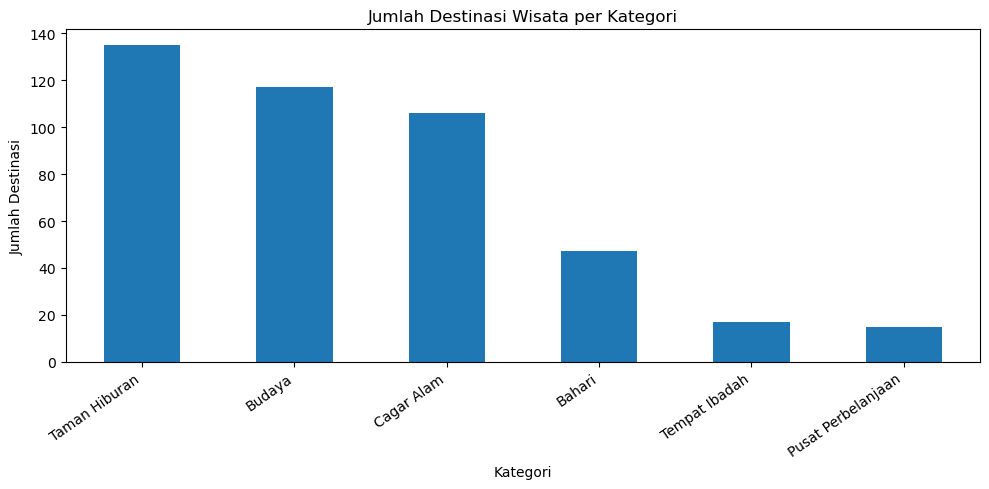

In [6]:
category_counts = df["Category"].value_counts()

plt.figure(figsize=(10, 5))
category_counts.plot(kind="bar")
plt.title("Jumlah Destinasi Wisata per Kategori")
plt.xlabel("Kategori")
plt.ylabel("Jumlah Destinasi")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

In [7]:
print("5 NILAI PERTAMA KOLOM UNNAMED: 12:")
display(df["Unnamed: 12"].head())

print("\n5 NILAI TERAKHIR KOLOM UNNAMED: 12:")
display(df["Unnamed: 12"].tail())

print("\nAPAKAH NILAINYA SAMA DENGAN NOMOR BARIS 1-437?")
print(
    df["Unnamed: 12"].reset_index(drop=True).equals(
        pd.Series(range(1, len(df) + 1), name="Unnamed: 12")
    )
)

5 NILAI PERTAMA KOLOM UNNAMED: 12:


0    1
1    2
2    3
3    4
4    5
Name: Unnamed: 12, dtype: int64


5 NILAI TERAKHIR KOLOM UNNAMED: 12:


432    433
433    434
434    435
435    436
436    437
Name: Unnamed: 12, dtype: int64


APAKAH NILAINYA SAMA DENGAN NOMOR BARIS 1-437?
True


In [8]:
print("10 DESTINASI DENGAN HARGA TERTINGGI:")

display(
    df[["Place_Name", "City", "Category", "Price", "Rating"]]
    .sort_values("Price", ascending=False)
    .head(10)
)

10 DESTINASI DENGAN HARGA TERTINGGI:


,Place_Name,City,Category,Price,Rating
13,Pulau Pelangi,Jakarta,Bahari,900000,4.8
143,Goa Jomblang,Yogyakarta,Cagar Alam,500000,4.6
296,Mountain View Golf Club,Bandung,Cagar Alam,375000,4.4
71,Waterboom PIK (Pantai Indah Kapuk),Jakarta,Taman Hiburan,300000,4.4
213,Trans Studio Bandung,Bandung,Taman Hiburan,280000,4.5
2,Dunia Fantasi,Jakarta,Taman Hiburan,270000,4.6
119,Bukit Panguk Kediwung,Yogyakarta,Budaya,250000,4.5
161,Kampung Wisata Dipowinatan,Yogyakarta,Budaya,220000,4.5
381,Kampoeng Kopi Banaran,Semarang,Taman Hiburan,200000,4.3
82,Alive Museum Ancol,Jakarta,Taman Hiburan,200000,4.3


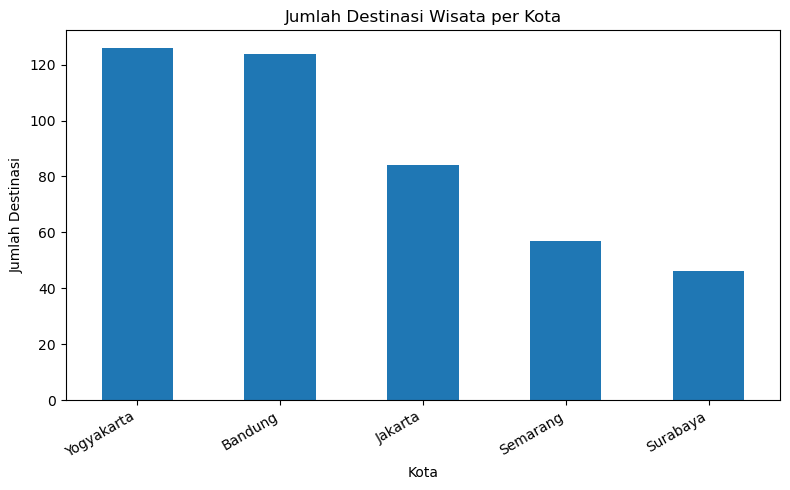

In [9]:
city_counts = df["City"].value_counts()

plt.figure(figsize=(8, 5))
city_counts.plot(kind="bar")
plt.title("Jumlah Destinasi Wisata per Kota")
plt.xlabel("Kota")
plt.ylabel("Jumlah Destinasi")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

Statistik panjang deskripsi (jumlah kata):


count     437.00
mean       99.19
std        74.22
min        11.00
25%        64.00
50%        85.00
75%       116.00
max      1180.00
Name: panjang_deskripsi, dtype: float64

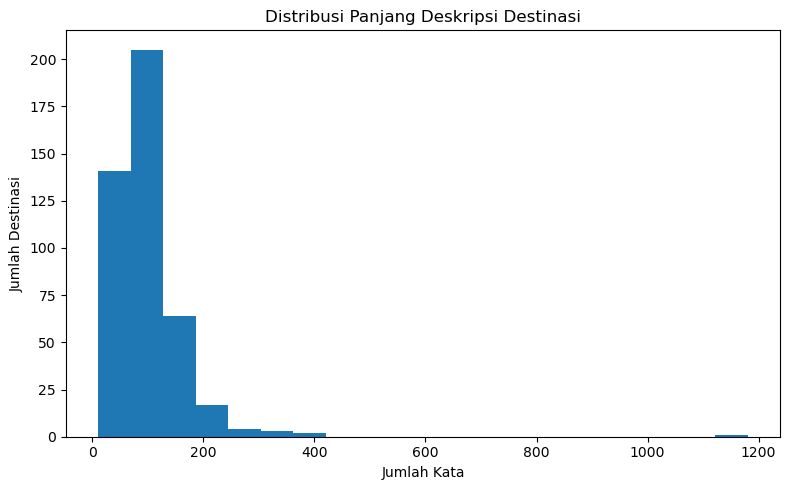

In [3]:
df["panjang_deskripsi"] = (
    df["Description"].astype(str).str.split().str.len()
)

print("Statistik panjang deskripsi (jumlah kata):")
display(df["panjang_deskripsi"].describe().round(2))

plt.figure(figsize=(8, 5))
df["panjang_deskripsi"].plot(kind="hist", bins=20)

plt.title("Distribusi Panjang Deskripsi Destinasi")
plt.xlabel("Jumlah Kata")
plt.ylabel("Jumlah Destinasi")
plt.tight_layout()
plt.show()

In [4]:
display(
    df[["Place_Name", "Category", "City", "Description"]]
    .sample(5, random_state=42)
)

,Place_Name,Category,City,Description
395,Monumen Kapal Selam,Budaya,Surabaya,"Monumen Kapal Selam, atau disingkat Monkasel, ..."
78,Taman Spathodea,Taman Hiburan,Jakarta,Objek Wisata Taman Spathodea di Jagakarsa DKI ...
278,Masjid Agung Trans Studio Bandung,Tempat Ibadah,Bandung,Masjid Agung Trans Studio Bandung (TSB) berdir...
305,Sungai Palayangan,Cagar Alam,Bandung,Sungai Palayangan terletak di Kawasan Objek Wi...
325,Taman Kupu-Kupu Cihanjuang,Cagar Alam,Bandung,"Taman Kupu-Kupu Cihanjuang Bandung ini,seperti..."


## Kesimpulan Eksplorasi Dataset

Dataset yang digunakan dalam proyek WisataFinder terdiri dari 437 destinasi wisata yang tersebar di lima kota, yaitu Yogyakarta, Bandung, Jakarta, Semarang, dan Surabaya. Dataset mencakup enam kategori wisata.

Hasil pemeriksaan menunjukkan bahwa tidak terdapat baris duplikat maupun ID destinasi duplikat. Kolom `Unnamed: 11` tidak memiliki nilai, sedangkan `Unnamed: 12` berisi nomor urut tambahan. Kedua kolom tersebut dihapus pada tahap preprocessing.

Kolom `Time_Minutes` memiliki 232 nilai kosong. Nilai tersebut dipertahankan karena durasi kunjungan bukan komponen utama pencarian berbasis teks.

Panjang deskripsi memiliki rata-rata 99,19 kata, median 85 kata, minimum 11 kata, dan maksimum 1.180 kata. Variasi panjang ini perlu diperhatikan saat mengevaluasi relevansi hasil pencarian.

Kolom nama destinasi, kategori, kota, dan deskripsi digabungkan menjadi `search_text` pada tahap preprocessing. Teks tersebut akan digunakan sebagai masukan metode TF-IDF dan Cosine Similarity untuk mengambil destinasi yang relevan dengan kueri pengguna.

Tahap selanjutnya adalah membangun dan menguji mesin pencarian, kemudian mengevaluasi kualitas hasilnya menggunakan kueri yang mewakili kebutuhan pengguna.